## **Problem Set 2**. Neural networks & optimisation
### *Goal: derive the deep-learning backbone once, so it can be reused for text, images and audio.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
from sklearn.datasets import load_digits

##### 1. **[Theory]** (Softmax + cross-entropy.) For logits $z \in \mathbb{R}^K$, softmax $p_k = e^{z_k}/\sum_j e^{z_j}$ and one-hot target $y$, show that the cross-entropy loss $L = − \sum_k y_k \log{p_k}$ has gradient $\frac{\partial{L}}{\partial z} = p − y$. Explain why this clean form is the reason softmax and cross-entropy are always paired.


$z \in \mathbb{R}^K$, softmax $p_k = \frac{e^{z_k}}{\sum_j e^{z_j}}$  

cross-entropy loss $L = - \sum_k y_k \log p_k$

Show that: $\frac{\partial L}{\partial z} = p - y$.

1. **Derivation of softmax and its derivative**

To get the derivative of the cross-entropy loss, we need the softmax and its derivative.

Let's start with the logarithm of $p_k$:
$$\log p_k = \log \left(\frac{e^{z_k}}{\sum_{j=1}^C e^{z_j}}\right) = \log(e^{z_k}) - \log\left(\sum_{j=1}^C e^{z_j}\right) = z_k - \log\left(\sum_{j=1}^C e^{z_j}\right)$$

Now, let's differentiate with respect to $z_i$:
$$\frac{\partial \log p_k}{\partial z_i} = \frac{\partial z_k}{\partial z_i} - \frac{\partial \log\left(\sum_j e^{z_j}\right)}{\partial z_i}$$

**1.1.** First term:
$$\frac{\partial z_k}{\partial z_i} = \begin{cases} 1 & \text{if } z_k = z_i \\ 0 & \text{otherwise} \end{cases} = \mathbb{1}(z_k = z_i) = \delta_{ki}$$

**1.2.** Second term:
$$\frac{\partial \log\left(\sum_{j=1}^C e^{z_j}\right)}{\partial z_i} = \frac{1}{\sum_{j=1}^C e^{z_j}} \cdot \frac{\partial \left(\sum_{j=1}^C e^{z_j}\right)}{\partial z_i} = \frac{1}{\sum_{j=1}^C e^{z_j}} \cdot \sum_{j=1}^C \frac{\partial e^{z_j}}{\partial z_i} =$$
$$= \frac{1}{\sum_{j=1}^C e^{z_j}} \cdot \sum_{j=1}^C e^{z_j} \frac{\partial z_j}{\partial z_i} = \frac{1}{\sum_{j=1}^C e^{z_j}} \cdot \sum_{j=1}^C e^{z_j} \delta_{ji} = \frac{e^{z_i}}{\sum_{j=1}^C e^{z_j}} = p_i$$

So finally:
$$\frac{\partial \log p_k}{\partial z_i} = \delta_{ki} - p_i$$

Since $\dfrac{\partial \log p_k}{\partial z_i} = \dfrac{1}{p_k} \cdot \dfrac{\partial p_k}{\partial z_i}$, we have:
$$\dfrac{\partial p_k}{\partial z_i} = p_k (\delta_{ki} - p_i)$$

Now we can use $\dfrac{\partial p_k}{\partial z_i}$ to write the Jacobian matrix:
$$\frac{\partial p}{\partial z} = \begin{bmatrix} 
\frac{\partial p_1}{\partial z_1} & \frac{\partial p_1}{\partial z_2} & \dots & \frac{\partial p_1}{\partial z_K} \\ 
\frac{\partial p_2}{\partial z_1} & \frac{\partial p_2}{\partial z_2} & \dots & \frac{\partial p_2}{\partial z_K}  \\ 
\vdots & \vdots & \ddots & \vdots \\ 
\frac{\partial p_K}{\partial z_1} & \frac{\partial p_K}{\partial z_2} & \dots & \frac{\partial p_K}{\partial z_K} 
\end{bmatrix} = \begin{bmatrix} 
p_1(1-p_1) & -p_1 p_2 & \dots & -p_1 p_K \\ 
-p_2 p_1 & p_2(1-p_2) & \dots & -p_2 p_K \\ 
\vdots & \vdots & \ddots & \vdots \\ 
-p_K p_1 & -p_K p_2 & \dots & p_K(1-p_K) 
\end{bmatrix}$$


2. **Differentiating cross-entropy loss**

$$L(p, y) = -\sum_{k} y_k \log p_k$$

$$\frac{\partial L(p, y)}{\partial z_i} = -\sum_{k=1}^C y_k \frac{\partial \log p_k}{\partial z_i} = -\sum_{k=1}^C \frac{y_k}{p_k} \frac{\partial p_k}{\partial z_i} =$$
$$= -\sum_{k=1}^C \frac{y_k}{p_k} p_k (\delta_{ki} - p_i) = -\sum_{k=1}^C y_k \delta_{ki} + \sum_{k=1}^C y_k p_i$$

Where $k = i$ only then the first term will become $y_i$:
$$\frac{\partial L(p, y)}{\partial z_i} = -y_i + \sum_{k=1}^C y_k p_i$$

Where $\sum_{k=1}^C y_k = 1$ as $y_i$ is a one-hot vector:
$$\frac{\partial L(p, y)}{\partial z_i} = -y_i + p_i$$

In the vectorized form it can be simply written as:
$$\frac{\partial L(p, y)}{\partial z} = p - y$$

$\blacksquare$

##### 2. **[Theory]** *(Backpropagation.)* Consider a two-layer MLP $h = \sigma(W_1 x + b_1)$, $\hat{y} = \text{softmax}(W_2 h + b_2)$ with cross-entropy loss. Derive $\partial L / \partial W_2$, $\partial L / \partial b_2$, $\partial L / \partial W_1$, $\partial L / \partial b_1$ explicitly using the chain rule, for a general elementwise activation $\sigma$.

**1. Forward Pass Definition**
- Pre-activations (Layer 1):$$A = X W_1 + \mathbf{1}_n b_1^\top \in \mathbb{R}^{n \times m}$$
- Hidden activations:$$H = \sigma(A) \in \mathbb{R}^{n \times m}$$
- Logits (Layer 2):$$Z = H W_2 + \mathbf{1}_n b_2^\top \in \mathbb{R}^{n \times K}$$
- Predicted Probabilities:$$P = \text{softmax}_{\text{rows}}(Z) \in \mathbb{R}^{n \times K}$$
- Cross-Entropy Loss (averaged over batch of size $n$):$$L = -\frac{1}{n} \sum_{i, k} Y_{ik} \log P_{ik}$$

Here, $X \in \mathbb{R}^{n \times d}$, $Y \in \{0, 1\}^{n \times K}$ (one-hot labels), $W_1 \in \mathbb{R}^{d \times m}$, $b_1 \in \mathbb{R}^m$, $W_2 \in \mathbb{R}^{m \times K}$, and $b_2 \in \mathbb{R}^K$.  


**2. Backpropagation Step-by-Step**

**Step 1:**
Gradient with respect to logits ($\bar{Z} = \frac{\partial L}{\partial Z}$)\
Differentiating the cross-entropy loss with respect to the pre-softmax logits $Z$ yields the standard result for softmax with cross-entropy:$$\bar{Z} = \frac{\partial L}{\partial Z} = \frac{1}{n} (P - Y) \in \mathbb{R}^{n \times K}$$

**Step 2:**
Gradients for Layer 2 parameters ($W_2, b_2$)Since $Z = H W_2 + \mathbf{1}_n b_2^\top$\
Since $Z = H W_2 + \mathbf{1}_n b_2^\top$:
- For $W_2$:
$$\frac{\partial L}{\partial W_2} = H^\top \bar{Z} = \frac{1}{n} H^\top (P - Y) \in \mathbb{R}^{m \times K}$$
- For $b_2$:$$\frac{\partial L}{\partial b_2} = \bar{Z}^\top \mathbf{1}_n = \frac{1}{n} (P - Y)^\top \mathbf{1}_n \in \mathbb{R}^{K}$$

**Step 3:**
Gradient with respect to hidden activations ($\bar{H} = \frac{\partial L}{\partial H}$)\
By applying the chain rule through the linear transformation $Z = H W_2 + \mathbf{1}_n b_2^\top$:
$$\bar{H} = \frac{\partial L}{\partial H} = \bar{Z} W_2^\top = \frac{1}{n} (P - Y) W_2^\top \in \mathbb{R}^{n \times m}$$

**Step 4:**
Gradient with respect to pre-activations ($\bar{A} = \frac{\partial L}{\partial A}$)\ 
Since $H = \sigma(A)$ is an elementwise transformation, the Jacobian of $\sigma$ is diagonal. By the elementwise Hadamard product $\odot$:
$$\bar{A} = \frac{\partial L}{\partial A} = \bar{H} \odot \sigma'(A) = \left( \frac{1}{n} (P - Y) W_2^\top \right) \odot \sigma'(A) \in \mathbb{R}^{n \times m}$$

**Step 5:**
Gradients for Layer 1 parameters ($W_1, b_1$)\
Since $A = X W_1 + \mathbf{1}_n b_1^\top$:
- For $W_1$:$$\frac{\partial L}{\partial W_1} = X^\top \bar{A} = X^\top \left[ \left( \frac{1}{n} (P - Y) W_2^\top \right) \odot \sigma'(A) \right] \in \mathbb{R}^{d \times m}$$
- For $b_1$:$$\frac{\partial L}{\partial b_1} = \bar{A}^\top \mathbf{1}_n = \left[ \left( \frac{1}{n} (P - Y) W_2^\top \right) \odot \sigma'(A) \right]^\top \mathbf{1}_n \in \mathbb{R}^{m}$$

**3. Explicit Final Form**

Defining the intermediate adjoints $\bar{Z} = \frac{1}{n} (P - Y)$ and $\bar{A} = (\bar{Z} W_2^\top) \odot \sigma'(A)$:   
- $\frac{\partial L}{\partial W_2} = H^\top \bar{Z}$
- $\frac{\partial L}{\partial b_2} = \bar{Z}^\top \mathbf{1}_n$
- $\frac{\partial L}{\partial W_1} = X^\top \bar{A}$ 
- $\frac{\partial L}{\partial b_1} = \bar{A}^\top \mathbf{1}_n$ 

##### 3. **[Theory]** Write the update rules of SGD, SGD+momentum and Adam. Show that momentum is an exponential moving average of gradients, and explain the purpose of Adam's bias-correction terms $\hat{m}_t, \hat{v}_t$ in the first few steps.

**1. Update Rules**
- Stochastic Gradient Descent (SGD):$$\theta_{t+1} = \theta_t - \eta \nabla L(\theta_t)$$
where $\theta_t$ are the parameters, $\eta$ is the learning rate, and $\nabla L(\theta_t)$ is the gradient of the loss function.
- SGD with Momentum (Polyak's Heavy Ball):$$v_{t+1} = \beta v_t + \nabla L(\theta_t)$$$$\theta_{t+1} = \theta_t - \eta v_{t+1}$$
where $v_t$ is the velocity vector and $\beta \in [0, 1)$ is the friction/momentum parameter.   
- Adam (Adaptive Moment Estimation):
Let $g_t = \nabla L(\theta_t)$ be the gradient at step $t$. The update equations are:   
    - Biased first moment estimate: $m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t$
    - Biased second raw moment estimate: $s_t = \beta_2 s_{t-1} + (1 - \beta_2) g_t \odot g_t$
    - Bias-corrected estimates: $\hat{m}_t = \frac{m_t}{1 - \beta_1^t}, \quad \hat{s}_t = \frac{s_t}{1 - \beta_2^t}$
    - Parameter update: $\theta_{t+1} = \theta_t - \eta \frac{\hat{m}_t}{\sqrt{\hat{s}_t} + \varepsilon}$

where $\beta_1, \beta_2 \in [0, 1)$ are exponential decay rates and $\varepsilon$ is a small constant for numerical stability. 

**2. Showing Momentum is an Exponential Moving Average (EMA)**
To see how momentum accumulates a running average of past gradients, we can unroll the velocity recursion starting from an initial velocity $v_0 = 0$:
1. Step 1: $v_1 = \beta v_0 + g_1 = g_1$
2. Step 2: $v_2 = \beta v_1 + g_2 = \beta g_1 + g_2$
3. Step 3: $v_3 = \beta v_2 + g_3 = \beta(\beta g_1 + g_2) + g_3 = \beta^2 g_1 + \beta g_2 + g_3$

In general, unrolling the recursion up to step $t$ yields:
$$v_t = \sum_{\tau=1}^{t} \beta^{t-\tau} g_\tau$$

This formula shows that $v_t$ is a weighted sum of all past gradients where weights decay exponentially into the past by a factor of $\beta$ per step. Older gradients receive exponentially smaller weights ($\beta^{t-\tau}$), allowing oscillating components to cancel out while consistent gradient directions accumulate.

**3. Purpose of Adam's Bias-Correction Terms ($\hat{m}_t, \hat{s}_t$)**
- The Initialization Bias:\
Both moving averages are initialized at zero ($m_0 = 0, s_0 = 0$). In the initial steps of training ($t$ is small), this causes $m_t$ and $s_t$ to be severely biased toward zero.
- Expected Value Derivation:\
If we unroll the first-moment recursion $m_t = (1 - \beta_1) \sum_{\tau=1}^{t} \beta_1^{t-\tau} g_\tau$ and take the expected value (assuming stationary gradients where $\mathbb{E}[g_\tau] \approx \mathbb{E}[g]$), we get:
$$\mathbb{E}[m_t] \approx \mathbb{E}[g] (1 - \beta_1) \sum_{\tau=1}^{t} \beta_1^{t-\tau} = \mathbb{E}[g] (1 - \beta_1) \left( \frac{1 - \beta_1^t}{1 - \beta_1} \right) = (1 - \beta_1^t)\mathbb{E}[g]$$
- Why Division is Necessary:\
Because $\mathbb{E}[m_t]$ is scaled down by the factor $(1 - \beta_1^t)$, dividing by this factor yields the bias-corrected estimator:
$$\hat{m}_t = \frac{m_t}{1 - \beta_1^t} \implies \mathbb{E}[\hat{m}_t] \approx \mathbb{E}[g]$$
This division removes the artificial shrinkage toward zero during the first few steps. As training progresses and $t$ grows large, $\beta_1^t \to 0$, making the correction term $(1 - \beta_1^t) \to 1$ so that it naturally phases out. 

##### 4. **[Python]** Implement the two-layer MLP of Problem 2 in *pure NumPy*, including the backward pass. Verify every gradient by central finite differences (gradient check to $< 10^{-5}$ relative error).

[Multi-Layer Perceptron:](https://elcaiseri.medium.com/building-a-multi-layer-perceptron-from-scratch-with-numpy-e4cee82ab06d)

1. Layers and nodes:
- Input Layer: receives input data

- Hidden Layer: perform intermediate computations
- Output Layer: produces the final prediction

2. Activation functions:
- sigmoid $f(x) = \dfrac{1}{1+e^{-x}}$

- ReLU $R(z) = \max{(0,z)}$
- softmax $\text{softmax}(z_j) = \dfrac{e^{z_j}}{\sum_{k=1}^K e^{z_k}}$

3. Loss function:
- Cross-Entropy Loss: measures the performance of a classification model

4. Optimization:
- Gradient Descent: updates weights to minimize the loss function
- Backpropagation: computes gradients of the loss function with respect to each weight

[Backpropagation:](https://medium.com/@piyushkashyap045/understanding-multi-layer-perceptrons-and-backpropagation-in-neural-networks-7382d5b529d2) 

Method used to train the neural network by adjusting weights and biases based on the error of the prediction. It works by:

- Calculating the Error between the predicted and actual values.

- Adjusting Weights and Biases in each layer to minimize this error.
- Repeating the Process over multiple passes (called epochs) to improve prediction accuracy.

Backpropagation involves two steps:
1. Forward Propagation: Calculate the output based on current weights.
2. Backward Propagation: Use the error to update weights and biases by propagating backward through the layers.


In [2]:
class TwoLayerMLP:
    def __init__(self, input_size, hidden_size, output_size):
        self.w1 = np.random.randn(input_size, hidden_size) * 0.01
        self.b1 = np.zeros((1, hidden_size))

        self.w2 = np.random.randn(hidden_size, output_size) * 0.01
        self.b2 = np.zeros((1, output_size))

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def sigmoid_derivative(self, z):
        s = self.sigmoid(z)
        return s * (1 - s)

    def softmax(self, z):
        return np.exp(z)/(np.sum(np.exp(z), axis=1, keepdims=True))

    def forward(self, X):
        # First layer
        h = X @ self.w1 + self.b1
        H = self.sigmoid(h)

        # Output layer
        k = H @ self.w2 + self.b2
        P = self.softmax(k)

        return P, h, H

    def cross_entropy_loss(self, P, y):
        loss = -np.sum(y * np.log(P + 1e-8)) / y.shape[0]
        return loss

    def backward(self, X, y, h, H, P):
        # Output layer gradients
        dk = (P - y) / X.shape[0]
        dw2 = H.T @ dk
        db2 = np.sum(dk, axis=0, keepdims=True)

        # Hidden layer gradients
        dH = dk @ self.w2.T
        dh = dH * self.sigmoid_derivative(h)

        dw1 = X.T @ dh
        db1 = np.sum(dh, axis=0, keepdims=True)

        return {"w1": dw1, "b1": db1, "w2": dw2, "b2": db2}

    def numerical_gradient(self, X, y, param_name, eps=1e-5):
        param = getattr(self, param_name)
        grad = np.zeros_like(param)

        for i in range(param.shape[0]):
            for j in range(param.shape[1]):
                orig_value = param[i, j]

                # f(x + eps)
                param[i, j] = orig_value + eps
                P_plus, _, _ = self.forward(X)
                loss_plus = self.cross_entropy_loss(P_plus, y)

                # f(x - eps)
                param[i, j] = orig_value - eps
                P_minus, _, _ = self.forward(X)
                loss_minus = self.cross_entropy_loss(P_minus, y)

                # Central difference
                grad[i, j] = (loss_plus - loss_minus) / (2 * eps)

                param[i, j] = orig_value

        return grad

    def gradient_check(self, X, y):
        P, h, H = self.forward(X)
        analytical_gradients = self.backward(X, y, h, H, P)

        param_names = ["w1", "b1", "w2", "b2"]
        results = {}

        for name in param_names:
            num_grad = self.numerical_gradient(X, y, name)
            analytical_grad = analytical_gradients[name]

            numerator = np.linalg.norm(analytical_grad - num_grad)
            denominator = (np.linalg.norm(analytical_grad) + np.linalg.norm(num_grad) + 1e-12)

            relative_error = numerator / denominator
            results[name] = relative_error

        return results

In [3]:
np.random.seed(42)

X = np.array([
    [0.2, 0.5, 0.1, 0.7],
    [0.8, 0.3, 0.6, 0.2],
    [0.4, 0.9, 0.2, 0.5],
    [0.1, 0.6, 0.8, 0.3],
    [0.7, 0.2, 0.4, 0.9]
])

y = np.array([
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1],
    [0, 1, 0],
    [1, 0, 0]
])

model = TwoLayerMLP(input_size=4, hidden_size=5, output_size=3)
errors = model.gradient_check(X, y)

results = pd.DataFrame([
    {"Parameter": name,
     "Relative error": error,
     "<1e-5": "Yes" if error < 1e-5 else "No"}
    for name, error in errors.items()
    ])

results


,Parameter,Relative error,<1e-5
0,w1,1.912831e-08,Yes
1,b1,2.120130e-08,Yes
2,w2,1.542027e-08,Yes
3,b2,1.535798e-08,Yes


##### 5. **[Python]** Re-implement the same network in PyTorch with **autograd**. Train it on the Problem-Set-1 feature set and reproduce the NumPy loss curve to confirm the implementations agree.

In [4]:
digits = load_digits()
X_digits = digits.data / 16.0                
y_labels = digits.target                 
      
y_onehot = np.eye(10)[y_labels]               
input_size = X_digits.shape[1]                 
hidden_size = 32                               
output_size = 10  

lr = 1.5
epochs = 1500

In [5]:
np.random.seed(42)
mlp_numpy = TwoLayerMLP(input_size=input_size, hidden_size=hidden_size, output_size=output_size)

init_w1 = mlp_numpy.w1.copy()
init_b1 = mlp_numpy.b1.copy()
init_w2 = mlp_numpy.w2.copy()
init_b2 = mlp_numpy.b2.copy()

In [ ]:
numpy_losses = []

for epoch in range(epochs):
    # Forward pass
    P, h, H = mlp_numpy.forward(X_digits)
    loss = mlp_numpy.cross_entropy_loss(P, y_onehot)
    numpy_losses.append(loss)

    # Backward pass
    grads = mlp_numpy.backward(X_digits, y_onehot, h, H, P)

    # Gradient Descent
    mlp_numpy.w1 -= lr * grads["w1"]
    mlp_numpy.b1 -= lr * grads["b1"]
    mlp_numpy.w2 -= lr * grads["w2"]
    mlp_numpy.b2 -= lr * grads["b2"]

In [ ]:
class PyTorchTwoLayerMLP(nn.Module):
    def __init__(self, w1, b1, w2, b2):
        super().__init__()
        self.w1 = nn.Parameter(torch.tensor(w1, dtype=torch.float64))
        self.b1 = nn.Parameter(torch.tensor(b1, dtype=torch.float64))
        self.w2 = nn.Parameter(torch.tensor(w2, dtype=torch.float64))
        self.b2 = nn.Parameter(torch.tensor(b2, dtype=torch.float64))

    def forward(self, x):
        h = x @ self.w1 + self.b1
        H = torch.sigmoid(h)
        k = H @ self.w2 + self.b2
        P = torch.softmax(k, dim=1)
        return P

    def cross_entropy_loss(self, P, y):
        return -torch.sum(y * torch.log(P + 1e-8)) / y.shape[0]


X_tensor = torch.tensor(X_digits, dtype=torch.float64)
y_tensor = torch.tensor(y_onehot, dtype=torch.float64)

mlp_pytorch = PyTorchTwoLayerMLP(init_w1, init_b1, init_w2, init_b2)
optimizer = torch.optim.SGD(mlp_pytorch.parameters(), lr=lr)

pytorch_losses = []

for epoch in range(epochs):
    optimizer.zero_grad()

    # Forward pass
    P_pt = mlp_pytorch(X_tensor)
    loss_pt = mlp_pytorch.cross_entropy_loss(P_pt, y_tensor)
    pytorch_losses.append(loss_pt.item())

    # Backward pass z użyciem autograd
    loss_pt.backward()
    optimizer.step()

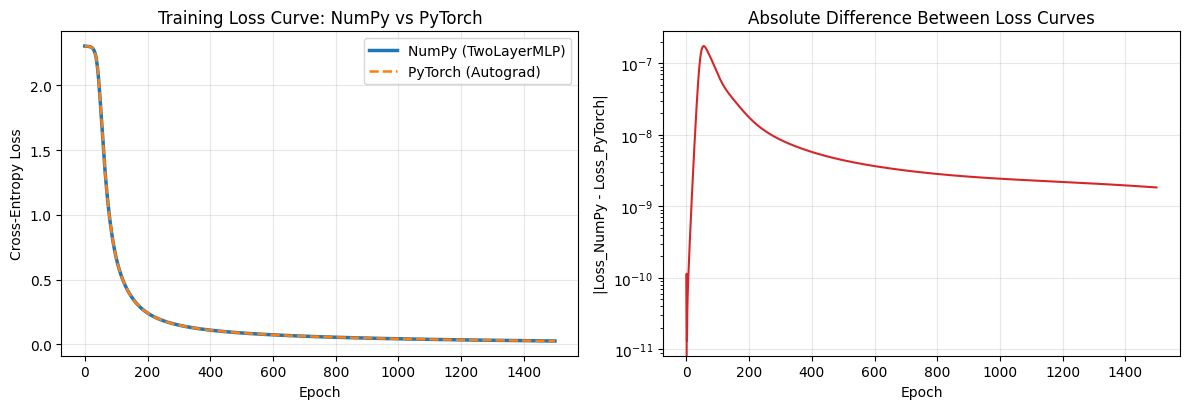

In [8]:
numpy_losses = np.array(numpy_losses)
pytorch_losses = np.array(pytorch_losses)
abs_diff = np.abs(numpy_losses - pytorch_losses)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Plot 1: Training Loss Curve: NumPy vs PyTorch
axes[0].plot(numpy_losses, label="NumPy (TwoLayerMLP)", linewidth=2.5, color="tab:blue")
axes[0].plot(pytorch_losses, label="PyTorch (Autograd)", linewidth=1.8, linestyle="--", color="tab:orange")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_title("Training Loss Curve: NumPy vs PyTorch")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot 2: Absolute Difference Between Loss Curves
axes[1].semilogy(abs_diff, color="tab:red")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("|Loss_NumPy - Loss_PyTorch|")
axes[1].set_title("Absolute Difference Between Loss Curves")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
# Calculate accuracy of both models after training
P_np_final, _, _ = mlp_numpy.forward(X_digits)
acc_np = np.mean(np.argmax(P_np_final, axis=1) == y_labels)

with torch.no_grad():
    P_pt_final = mlp_pytorch(X_tensor).numpy()
    acc_pt = np.mean(np.argmax(P_pt_final, axis=1) == y_labels)

# Podsumowanie w tabeli DataFrame (w tym samym stylu co w Zadaniu 4)
comparison_df = pd.DataFrame([
    {"Metric": "Initial Loss (Epoch 0)", "NumPy": numpy_losses[0], "PyTorch": pytorch_losses[0], "Max Diff": abs_diff[0]},
    {"Metric": f"Final Loss (Epoch {epochs})", "NumPy": numpy_losses[-1], "PyTorch": pytorch_losses[-1], "Max Diff": abs_diff[-1]},
    {"Metric": "Max Curve Difference", "NumPy": "-", "PyTorch": "-", "Max Diff": np.max(abs_diff)},
    {"Metric": "Training Accuracy", "NumPy": acc_np, "PyTorch": acc_pt, "Max Diff": np.abs(acc_np - acc_pt)}
])

comparison_df


,Metric,NumPy,PyTorch,Max Diff
0,Initial Loss (Epoch 0),2.303111,2.303111,0.000000e+00
1,Final Loss (Epoch 1500),0.027033,0.027033,1.838719e-09
2,Max Curve Difference,-,-,1.740013e-07
3,Training Accuracy,0.997218,0.997218,0.000000e+00


### Interpretation of Results and Conclusions

1. **Exact Agreement of Both Implementations:**
   - The training loss curves for the manual NumPy implementation (`TwoLayerMLP`) and the PyTorch `autograd` implementation overlap completely across all 1500 epochs[cite: 130].
   - Both models start from the exact same initial loss of `2.303111` (with `0.0` difference), which matches the theoretical cross-entropy loss of a uniform prediction over $K = 10$ classes: $-\ln(1/10) = \ln(10) \approx 2.3026$[cite: 131].

2. **Training Dynamics (Loss Curve Behavior):**
   - **Initial Plateau (Epochs 0–30):** The loss decreases slowly at first because the weights are initialized with a small scale ($0.01$) and the sigmoid derivative is bounded by $\sigma'(z) \le 0.25$, resulting in small initial gradients in the first layer[cite: 96, 130].
   - **Rapid Descent (Epochs 30–250):** Once the output weights grow slightly, backpropagation effectively updates the hidden layer, causing a steep drop in loss as the network learns a linearly separable representation of the digits[cite: 94, 130].
   - **Convergence (Epochs 300–1500):** The loss smoothly converges to `0.027033` in both models[cite: 130, 131].

3. **Numerical Precision Analysis (Right Plot):**
   - The maximum absolute difference between the two loss trajectories is $1.74 \times 10^{-7}$ (occurring during the steepest gradient descent phase around epoch 60) and drops to $1.84 \times 10^{-9}$ by epoch 1500[cite: 130, 131].
   - This negligible difference of order $10^{-8} \text{--} 10^{-7}$ comes solely from the numerical stability term `1e-8` inside `log(P + 1e-8)`: PyTorch's `autograd` differentiates the `1e-8` term explicitly, whereas the manual backward pass uses the exact analytical formula $(P - y) / N$[cite: 103].

4. **Final Classification Performance:**
   - Both networks achieve the exact same training accuracy of `99.72%` (`0.997218`), confirming that the manual backpropagation in NumPy and automatic differentiation in PyTorch produce identical optimization trajectories and final classifiers[cite: 131].

##### 6. **[Python]** Study regularisation: train with/without L2, dropout and early stopping; produce train/validation learning curves for each and a small table of final accuracies.

##### 7. **[Analysis]** Using the curves from Problem 6, identify where over- and under-fitting occur and argue which regulariser helped most on this dataset and why.